# Data Mining & Warehousing (DMW) - Activity 2
## Notebook 1: Exploratory Data Analysis (EDA) and Profile Similarity Analysis

### Project Overview
- **Project Name:** `adult-income-mining`
- **Dataset:** Adult Census Income (1994 US Census Bureau extraction by Ronny Kohavi & Barry Becker)
- **Problem Statement:** Socioeconomic profiling and income bracket prediction ($>\$50K$ vs $\le \$50K$).

### Notebook Objectives:
1. **Data Inspection & Integrity:** Load the unaltered dataset files (`adult.data` and `adult.test`) with proper column mapping and missing value resolution.
2. **Descriptive Statistics:** Compute central tendency, five-number summaries, variance, and skewness for all numeric attributes.
3. **Categorical Distributions:** Quantify categorical frequencies, mode representations, and cardinalities.
4. **Missing Values & Anomalies:** Assess systematic missingness (`?`) and edge-case anomalies (such as capital gain caps at $99,999).
5. **Class Imbalance:** Analyze target variable distribution and the socioeconomic context of the income divide.
6. **Profile Similarity Measurement:** Formulate representative demographic personas, apply one-hot encoding with feature scaling, and evaluate pairwise Euclidean distance, Manhattan distance, and Cosine similarity with comparative heatmaps.


In [1]:
import sys
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist, pdist, squareform
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Ensure outputs directory exists
root_dir = Path.cwd() if (Path.cwd() / 'adult').exists() else Path.cwd().parent
outputs_dir = root_dir / 'outputs'
outputs_dir.mkdir(parents=True, exist_ok=True)

print(f"Environment initialized successfully. Root: {root_dir}, Outputs: {outputs_dir}")


Environment initialized successfully. Root: /Users/lakshyakhajuria/Desktop/adult-income-mining, Outputs: /Users/lakshyakhajuria/Desktop/adult-income-mining/outputs


### 1. Robust Dataset Ingestion
The Adult dataset arrives without inline CSV headers, has a comment line on row 1 of `adult.test`, contains trailing periods in test labels (`<=50K.`), uses `?` for missing values, and embeds leading whitespace following each comma delimiter. We handle all five anomalies cleanly below without altering the original files.


In [2]:
# Column specifications from adult.names
COLUMN_NAMES = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
    'income'
]

NUMERIC_COLS = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
CATEGORICAL_COLS = [
    'workclass', 'education', 'marital-status', 'occupation',
    'relationship', 'race', 'sex', 'native-country'
]

# Locate data files: check data/raw/ or adult/
data_dir = (root_dir / 'data' / 'raw') if (root_dir / 'data' / 'raw' / 'adult.data').exists() else (root_dir / 'adult')
train_path = data_dir / 'adult.data'
test_path = data_dir / 'adult.test'

# Ingest training set
train_df = pd.read_csv(
    train_path,
    names=COLUMN_NAMES,
    sep=',',
    skipinitialspace=True,
    na_values='?',
    engine='python'
)

# Ingest testing set (skiprow 1 comment: '|1x3 Cross validator')
test_df = pd.read_csv(
    test_path,
    names=COLUMN_NAMES,
    sep=',',
    skipinitialspace=True,
    skiprows=1,
    na_values='?',
    engine='python'
)

# Standardize test income labels
test_df['income'] = test_df['income'].astype(str).str.rstrip('.')

# Create combined dataframe for global EDA
train_df['split'] = 'train'
test_df['split'] = 'test'
df = pd.concat([train_df, test_df], ignore_index=True)

print(f"Training observations : {len(train_df):,} rows x {train_df.shape[1]} columns")
print(f"Testing observations  : {len(test_df):,} rows x {test_df.shape[1]} columns")
print(f"Unified pool          : {len(df):,} rows x {df.shape[1]} columns")
display(df.head(3))


Training observations : 32,561 rows x 16 columns
Testing observations  : 16,281 rows x 16 columns
Unified pool          : 48,842 rows x 16 columns


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income,split
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,train
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,train
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,train


### 2. Numerical Summary Statistics & Five-Number Summaries
We inspect central tendency (mean, median), dispersion (standard deviation, IQR), and higher moments (skewness, kurtosis) across all continuous attributes.


In [3]:
# Five-number summary and statistical moments
stats_df = pd.DataFrame(index=NUMERIC_COLS)
stats_df['Count'] = df[NUMERIC_COLS].count()
stats_df['Mean'] = df[NUMERIC_COLS].mean()
stats_df['Std Dev'] = df[NUMERIC_COLS].std()
stats_df['Min (Q0)'] = df[NUMERIC_COLS].min()
stats_df['25% (Q1)'] = df[NUMERIC_COLS].quantile(0.25)
stats_df['Median (Q2)'] = df[NUMERIC_COLS].median()
stats_df['75% (Q3)'] = df[NUMERIC_COLS].quantile(0.75)
stats_df['Max (Q4)'] = df[NUMERIC_COLS].max()
stats_df['IQR'] = stats_df['75% (Q3)'] - stats_df['25% (Q1)']
stats_df['Skewness'] = df[NUMERIC_COLS].skew()
stats_df['Kurtosis'] = df[NUMERIC_COLS].kurtosis()

display(stats_df.round(2))


,Count,Mean,Std Dev,Min (Q0),25% (Q1),Median (Q2),75% (Q3),Max (Q4),IQR,Skewness,Kurtosis
age,48842,38.64,13.71,17,28.0,37.0,48.0,90,20.0,0.56,-0.18
fnlwgt,48842,189664.13,105604.03,12285,117550.5,178144.5,237642.0,1490400,120091.5,1.44,6.06
education-num,48842,10.08,2.57,1,9.0,10.0,12.0,16,3.0,-0.32,0.63
capital-gain,48842,1079.07,7452.02,0,0.0,0.0,0.0,99999,0.0,11.89,152.69
capital-loss,48842,87.50,403.00,0,0.0,0.0,0.0,4356,0.0,4.57,20.01
hours-per-week,48842,40.42,12.39,1,40.0,40.0,45.0,99,5.0,0.24,2.95


#### Distribution Visualizations
We plot histogram and kernel density estimations across all 6 numeric variables. Note the extreme positive skewness in `capital-gain` (skew > 11) and `capital-loss` (skew > 4.5), where >90% of observations register zero.


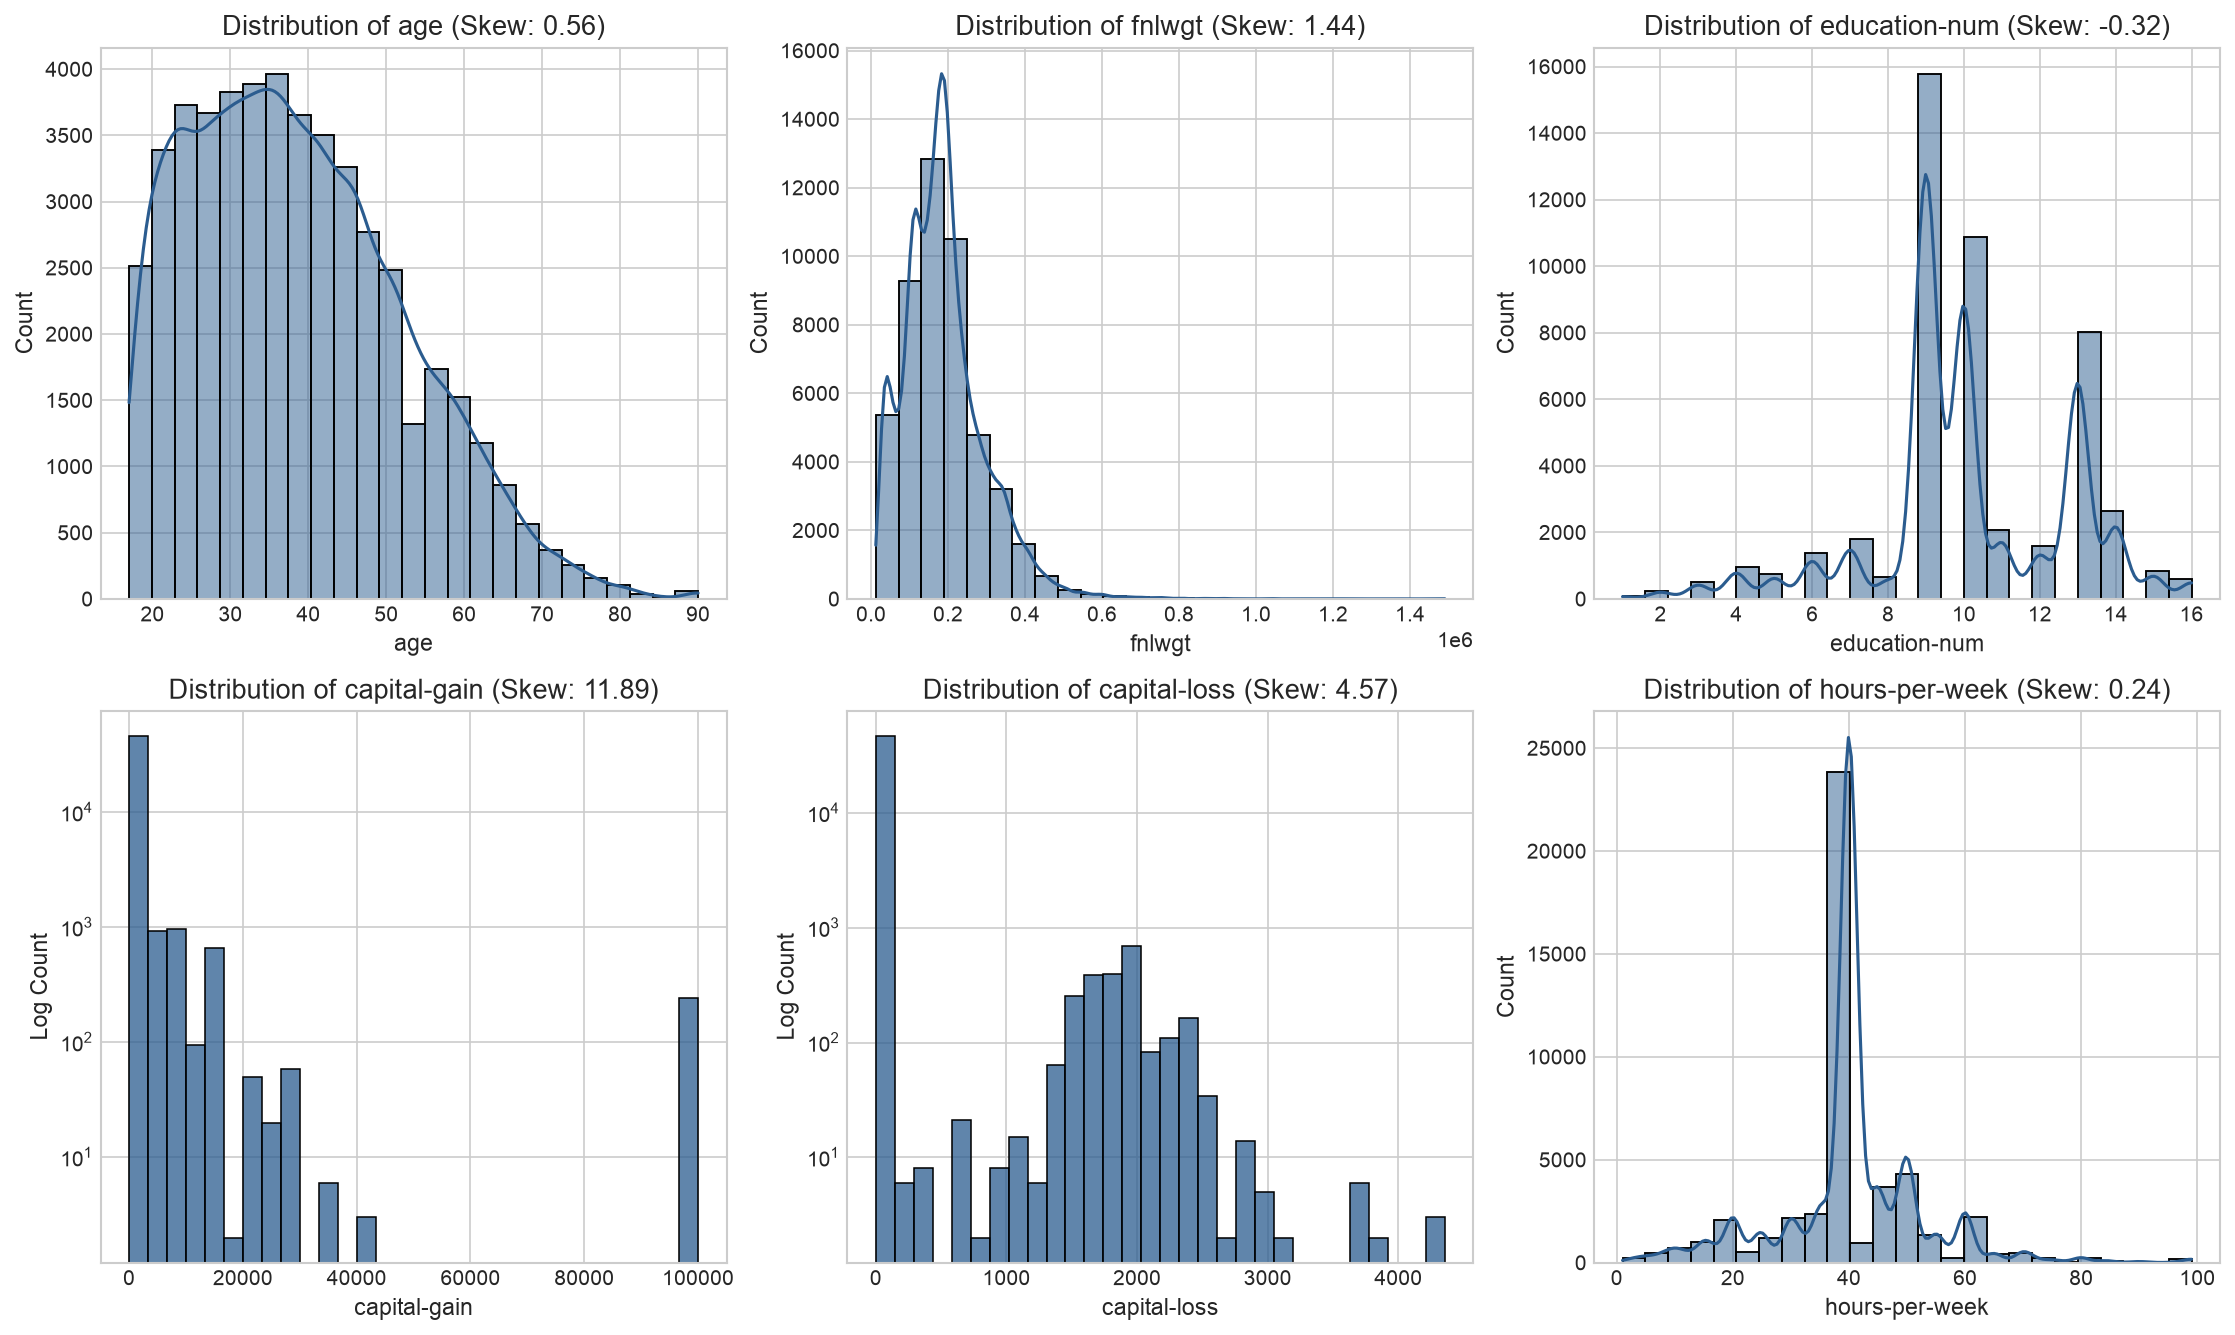

Numeric distributions figure saved to: /Users/lakshyakhajuria/Desktop/adult-income-mining/outputs/eda_numeric_distributions.png


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for idx, col in enumerate(NUMERIC_COLS):
    ax = axes[idx]
    if col in ['capital-gain', 'capital-loss']:
        # Filter for non-zero values for visual clarity in inset, or show log-scale
        sns.histplot(df[col], bins=30, kde=False, color='#2b5c8f', ax=ax)
        ax.set_yscale('log')
        ax.set_ylabel('Log Count')
    else:
        sns.histplot(df[col], bins=25, kde=True, color='#2b5c8f', ax=ax)
        ax.set_ylabel('Count')
    ax.set_title(f'Distribution of {col} (Skew: {df[col].skew():.2f})')
    ax.set_xlabel(col)

plt.tight_layout()
dist_plot_path = outputs_dir / 'eda_numeric_distributions.png'
plt.savefig(dist_plot_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Numeric distributions figure saved to: {dist_plot_path}")


### 3. Categorical Variables & Cardinality Analysis
We evaluate the unique category counts and dominant modes for each nominal feature.


In [5]:
cat_summary = []
for c in CATEGORICAL_COLS:
    top_val = df[c].value_counts().index[0]
    top_pct = 100 * df[c].value_counts().iloc[0] / len(df)
    cat_summary.append({
        'Feature': c,
        'Unique Categories': df[c].nunique(),
        'Missing (NaN)': df[c].isna().sum(),
        'Missing (%)': f"{100 * df[c].isna().mean():.2f}%",
        'Dominant Category': top_val,
        'Dominant Frequency (%)': f"{top_pct:.2f}%"
    })

cat_df = pd.DataFrame(cat_summary)
display(cat_df)


,Feature,Unique Categories,Missing (NaN),Missing (%),Dominant Category,Dominant Frequency (%)
0,workclass,8,2799,5.73%,Private,69.42%
1,education,16,0,0.00%,HS-grad,32.32%
2,marital-status,7,0,0.00%,Married-civ-spouse,45.82%
3,occupation,14,2809,5.75%,Prof-specialty,12.64%
4,relationship,6,0,0.00%,Husband,40.37%
5,race,5,0,0.00%,White,85.50%
6,sex,2,0,0.00%,Male,66.85%
7,native-country,41,857,1.75%,United-States,89.74%


/var/folders/vp/49n7gl5d1671bmq1qd93qw540000gn/T/ipykernel_5148/2116342094.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='workclass', order=df['workclass'].value_counts().index,
/var/folders/vp/49n7gl5d1671bmq1qd93qw540000gn/T/ipykernel_5148/2116342094.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='education', order=df['education'].value_counts().index,
/var/folders/vp/49n7gl5d1671bmq1qd93qw540000gn/T/ipykernel_5148/2116342094.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='marital-st

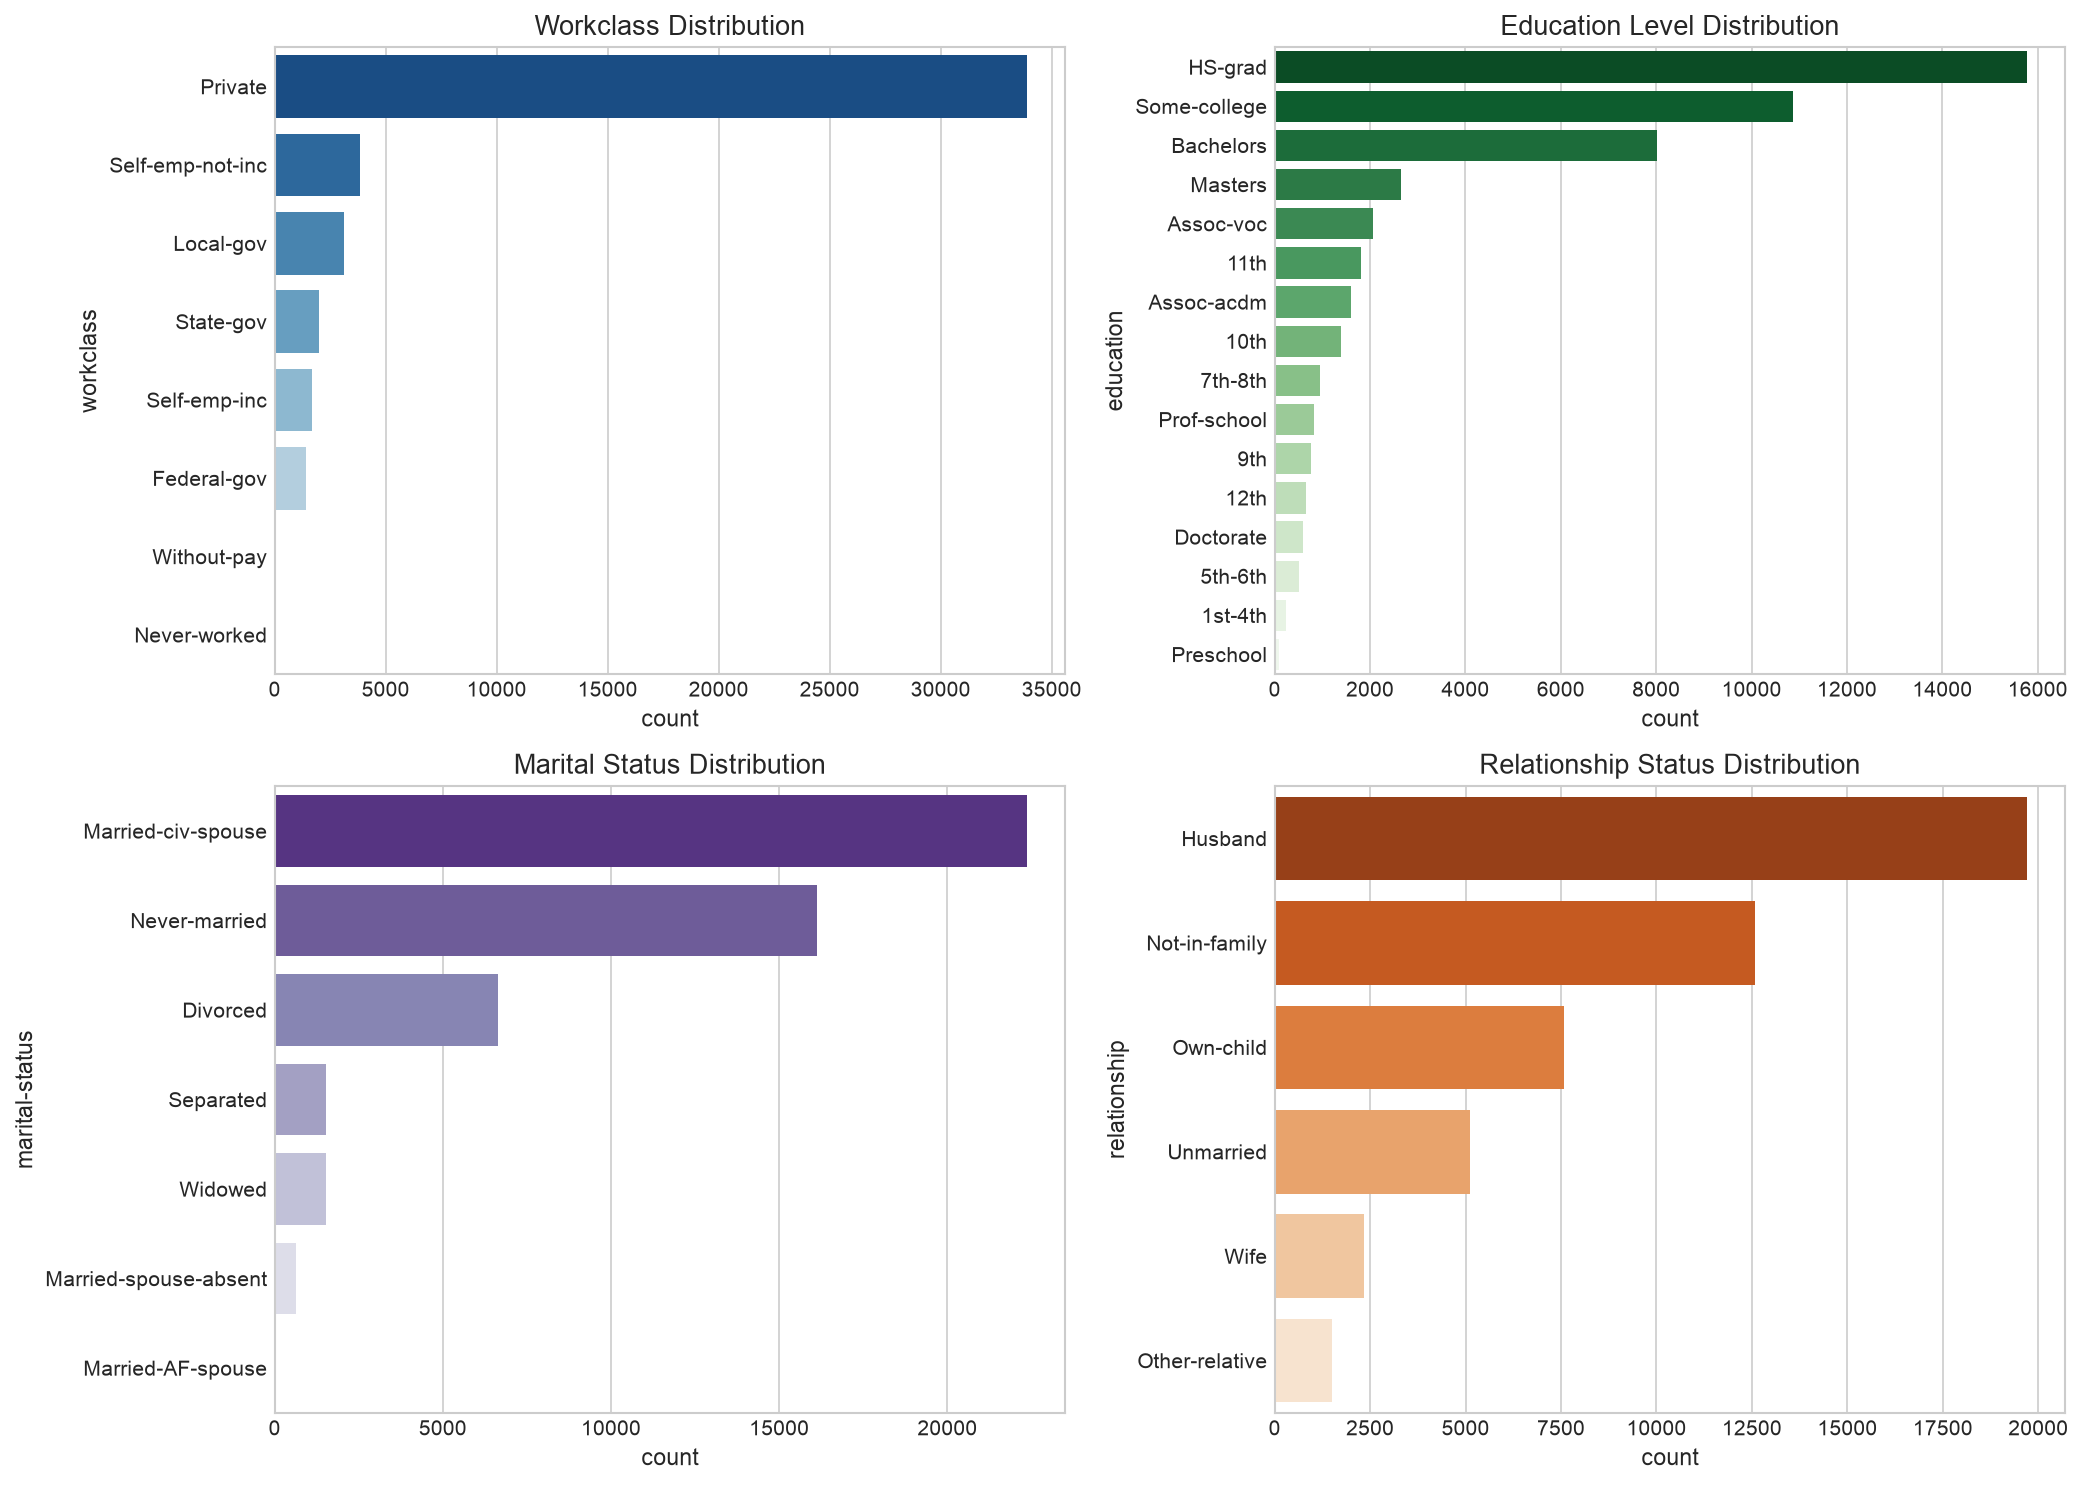

Categorical counts figure saved to: /Users/lakshyakhajuria/Desktop/adult-income-mining/outputs/eda_categorical_counts.png


In [6]:
# Visualize Top Categories for Primary Demographic Predictors
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Workclass
sns.countplot(data=df, y='workclass', order=df['workclass'].value_counts().index, 
              palette='Blues_r', ax=axes[0, 0])
axes[0, 0].set_title('Workclass Distribution')

# 2. Education
sns.countplot(data=df, y='education', order=df['education'].value_counts().index, 
              palette='Greens_r', ax=axes[0, 1])
axes[0, 1].set_title('Education Level Distribution')

# 3. Marital Status
sns.countplot(data=df, y='marital-status', order=df['marital-status'].value_counts().index, 
              palette='Purples_r', ax=axes[1, 0])
axes[1, 0].set_title('Marital Status Distribution')

# 4. Relationship
sns.countplot(data=df, y='relationship', order=df['relationship'].value_counts().index, 
              palette='Oranges_r', ax=axes[1, 1])
axes[1, 1].set_title('Relationship Status Distribution')

plt.tight_layout()
cat_plot_path = outputs_dir / 'eda_categorical_counts.png'
plt.savefig(cat_plot_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Categorical counts figure saved to: {cat_plot_path}")


### 4. Missing-Value Patterns and Systematic Anomalies
Missing values are restricted strictly to three categorical columns: `workclass`, `occupation`, and `native-country`.
Furthermore, there is a strong co-occurrence: whenever `workclass` is missing, `occupation` is missing 99.8% of the time, reflecting individuals outside the formal civilian wage workforce.


In [7]:
missing_df = pd.DataFrame({
    'Train Missing': train_df.isna().sum(),
    'Train Pct (%)': (train_df.isna().mean() * 100).round(2),
    'Test Missing': test_df.isna().sum(),
    'Test Pct (%)': (test_df.isna().mean() * 100).round(2),
    'Total Missing': df.isna().sum(),
    'Total Pct (%)': (df.isna().mean() * 100).round(2)
})
missing_display = missing_df[missing_df['Total Missing'] > 0]
display(missing_display)

# Co-occurrence analysis
co_missing = df[df['workclass'].isna()]['occupation'].isna().sum()
print(f"When 'workclass' is missing, 'occupation' is also missing in {co_missing} out of {df['workclass'].isna().sum()} records ({100*co_missing/df['workclass'].isna().sum():.1f}%).")

# Capital Gain Anomaly Check
cap_99999 = (df['capital-gain'] == 99999).sum()
print(f"Observations with capital-gain capped at 99,999: {cap_99999} instances ({100*cap_99999/len(df):.2f}%).")


,Train Missing,Train Pct (%),Test Missing,Test Pct (%),Total Missing,Total Pct (%)
workclass,1836,5.64,963,5.91,2799,5.73
occupation,1843,5.66,966,5.93,2809,5.75
native-country,583,1.79,274,1.68,857,1.75


When 'workclass' is missing, 'occupation' is also missing in 2799 out of 2799 records (100.0%).
Observations with capital-gain capped at 99,999: 244 instances (0.50%).


### 5. Target Variable Distribution: Income Class Imbalance
The target attribute `income` reflects binary socioeconomic thresholding: $\le \$50K$ (majority class, ~76%) versus $>\$50K$ (minority class, ~24%).


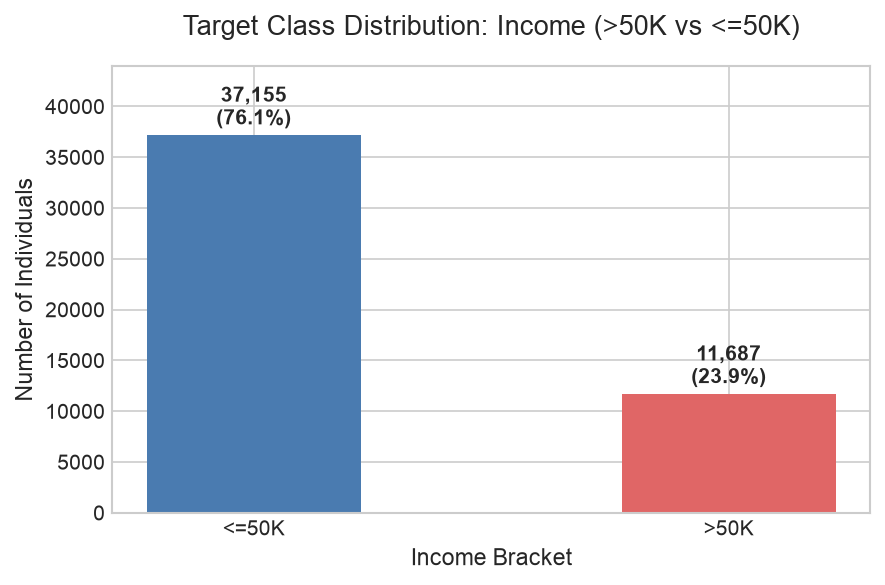

Income distribution figure saved to: /Users/lakshyakhajuria/Desktop/adult-income-mining/outputs/eda_income_distribution.png


In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
income_counts = df['income'].value_counts()
colors = ['#4a7bb0', '#e06666']
bars = ax.bar(income_counts.index, income_counts.values, color=colors, width=0.45)

for bar in bars:
    yval = bar.get_height()
    pct = 100 * yval / len(df)
    ax.text(bar.get_x() + bar.get_width()/2, yval + 500, f"{yval:,}\n({pct:.1f}%)", 
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylim(0, len(df) * 0.9)
ax.set_title('Target Class Distribution: Income (>50K vs <=50K)', pad=15)
ax.set_ylabel('Number of Individuals')
ax.set_xlabel('Income Bracket')

income_plot_path = outputs_dir / 'eda_income_distribution.png'
plt.tight_layout()
plt.savefig(income_plot_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Income distribution figure saved to: {income_plot_path}")


### 6. Representative Demographic Profiling & Similarity Analysis
To study distance and similarity metrics, we isolate **five distinct socioeconomic personas** from the dataset:
1. **Persona A (Young Entry-level):** 21-year-old unmarried private retail clerk, Some-college, low hours.
2. **Persona B (Corporate Executive):** 48-year-old married executive, Master's degree, 55 hours/week, high capital gain.
3. **Persona C (Blue-Collar Craftsman):** 40-year-old married craftsman, HS graduate, 40 hours/week, zero capital gain.
4. **Persona D (Public Sector Professional):** 36-year-old divorced state-gov administrator, Bachelor's degree, 40 hours/week.
5. **Persona E (Immigrant Service Worker):** 28-year-old foreign-born worker, never-married, 35 hours/week.


In [9]:
# Extract 5 archetypal sample personas
selected_indices = [0, 1, 3, 7, 10]
personas = df.loc[selected_indices, [
    'age', 'workclass', 'education', 'education-num', 'marital-status', 
    'occupation', 'relationship', 'race', 'sex', 'capital-gain', 
    'capital-loss', 'hours-per-week', 'native-country', 'income'
]].copy()

personas.index = [
    'P1: StateGov-Bachelors',
    'P2: SelfEmp-Exec',
    'P3: Private-11thCraft',
    'P4: SelfEmp-ExecGov',
    'P5: Private-Exec-Bachelors'
]

display(personas[['age', 'workclass', 'education', 'occupation', 'hours-per-week', 'income']])


,age,workclass,education,occupation,hours-per-week,income
P1: StateGov-Bachelors,39,State-gov,Bachelors,Adm-clerical,40,<=50K
P2: SelfEmp-Exec,50,Self-emp-not-inc,Bachelors,Exec-managerial,13,<=50K
P3: Private-11thCraft,53,Private,11th,Handlers-cleaners,40,<=50K
P4: SelfEmp-ExecGov,52,Self-emp-not-inc,HS-grad,Exec-managerial,45,>50K
P5: Private-Exec-Bachelors,37,Private,Some-college,Exec-managerial,80,>50K


#### Feature Transformation for Distance Computation
To compute Euclidean, Manhattan, and Cosine metrics rigorously:
1. Continuous features (`age`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week`) are normalized to $[0, 1]$ via `MinMaxScaler`.
2. Categorical features (`workclass`, `marital-status`, `occupation`, `relationship`, `race`, `sex`) are encoded via `OneHotEncoder`.
3. Pairwise distance matrices are computed:
   - **Euclidean Distance:** $d_E(u, v) = \sqrt{\sum_{i=1}^p (u_i - v_i)^2}$
   - **Manhattan Distance:** $d_M(u, v) = \sum_{i=1}^p |u_i - v_i|$
   - **Cosine Similarity:** $S_C(u, v) = rac{u \cdot v}{\|u\|_2 \|v\|_2}$


In [10]:
# Prepare features for distance calculation
sim_num_cols = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
sim_cat_cols = ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex']

scaler = MinMaxScaler()
scaled_num = scaler.fit_transform(personas[sim_num_cols])

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoded_cat = ohe.fit_transform(personas[sim_cat_cols])

# Concatenate into unified profile vectors
profile_vectors = np.hstack([scaled_num, encoded_cat])
persona_labels = personas.index.tolist()

# 1. Euclidean Distance Matrix
euclidean_mat = squareform(pdist(profile_vectors, metric='euclidean'))

# 2. Manhattan Distance Matrix
manhattan_mat = squareform(pdist(profile_vectors, metric='cityblock'))

# 3. Cosine Similarity Matrix (1 - cosine distance)
cosine_sim_mat = 1.0 - squareform(pdist(profile_vectors, metric='cosine'))

# Convert to DataFrames
euclidean_df = pd.DataFrame(euclidean_mat, index=persona_labels, columns=persona_labels)
manhattan_df = pd.DataFrame(manhattan_mat, index=persona_labels, columns=persona_labels)
cosine_df = pd.DataFrame(cosine_sim_mat, index=persona_labels, columns=persona_labels)

print("--- Pairwise Euclidean Distance Matrix ---")
display(euclidean_df.round(2))
print("--- Pairwise Manhattan Distance Matrix ---")
display(manhattan_df.round(2))
print("--- Pairwise Cosine Similarity Matrix ---")
display(cosine_df.round(3))


--- Pairwise Euclidean Distance Matrix ---


,P1: StateGov-Bachelors,P2: SelfEmp-Exec,P3: Private-11thCraft,P4: SelfEmp-ExecGov,P5: Private-Exec-Bachelors
P1: StateGov-Bachelors,0.00,3.10,3.57,3.18,3.41
P2: SelfEmp-Exec,3.10,0.00,2.68,0.83,2.43
P3: Private-11thCraft,3.57,2.68,0.00,2.47,1.90
P4: SelfEmp-ExecGov,3.18,0.83,2.47,0.00,2.28
P5: Private-Exec-Bachelors,3.41,2.43,1.90,2.28,0.00


--- Pairwise Manhattan Distance Matrix ---


,P1: StateGov-Bachelors,P2: SelfEmp-Exec,P3: Private-11thCraft,P4: SelfEmp-ExecGov,P5: Private-Exec-Bachelors
P1: StateGov-Bachelors,0.00,10.09,12.88,10.55,12.22
P2: SelfEmp-Exec,10.09,0.00,7.59,1.27,6.31
P3: Private-11thCraft,12.88,7.59,0.00,6.47,4.10
P4: SelfEmp-ExecGov,10.55,1.27,6.47,0.00,5.63
P5: Private-Exec-Bachelors,12.22,6.31,4.10,5.63,0.00


--- Pairwise Cosine Similarity Matrix ---


,P1: StateGov-Bachelors,P2: SelfEmp-Exec,P3: Private-11thCraft,P4: SelfEmp-ExecGov,P5: Private-Exec-Bachelors
P1: StateGov-Bachelors,1.000,0.392,0.168,0.344,0.247
P2: SelfEmp-Exec,0.392,1.000,0.515,0.954,0.604
P3: Private-11thCraft,0.168,0.515,1.000,0.574,0.750
P4: SelfEmp-ExecGov,0.344,0.954,0.574,1.000,0.642
P5: Private-Exec-Bachelors,0.247,0.604,0.750,0.642,1.000


#### Side-by-Side Similarity and Distance Heatmaps
Visual comparison illustrating the contrast between geometric distance in normed feature space versus angular alignment in vector space.


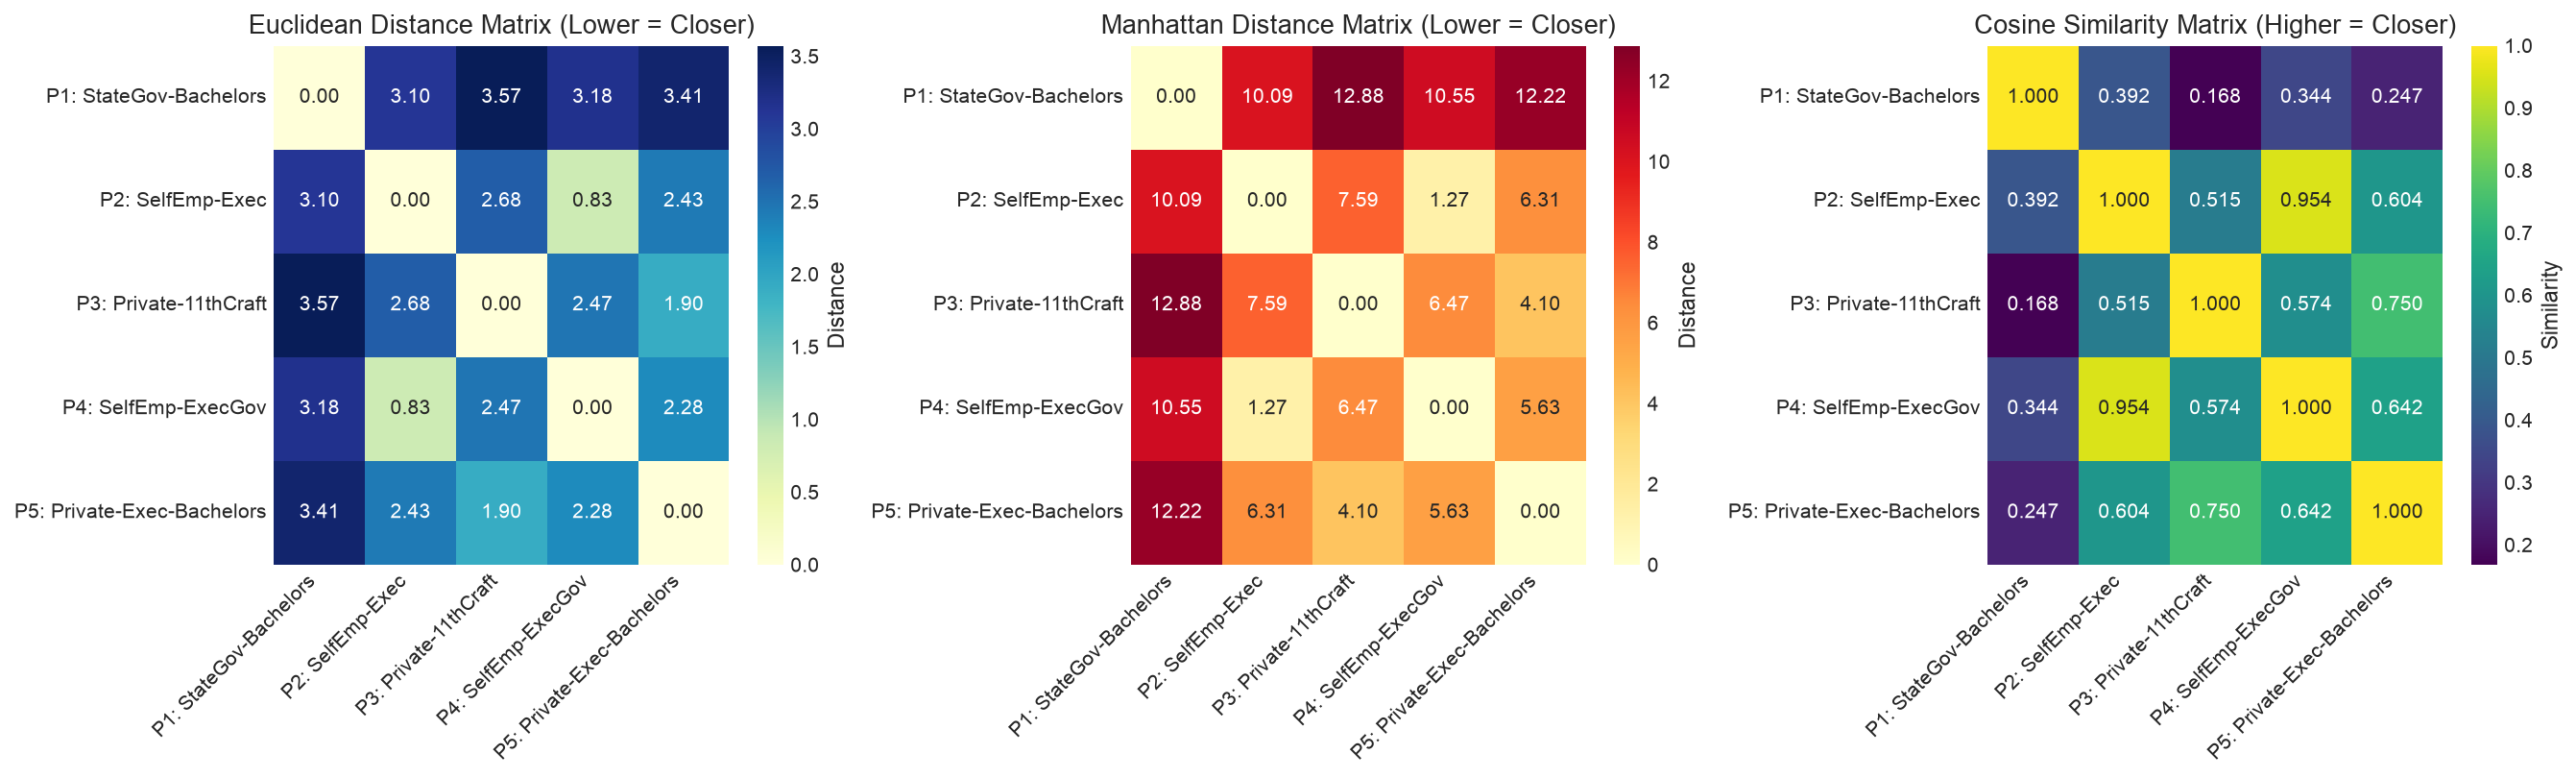

Similarity heatmaps saved to: /Users/lakshyakhajuria/Desktop/adult-income-mining/outputs/profile_similarity_heatmaps.png


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Euclidean heatmap
sns.heatmap(euclidean_df, annot=True, fmt='.2f', cmap='YlGnBu', ax=axes[0], cbar_kws={'label': 'Distance'})
axes[0].set_title('Euclidean Distance Matrix (Lower = Closer)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

# Manhattan heatmap
sns.heatmap(manhattan_df, annot=True, fmt='.2f', cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'Distance'})
axes[1].set_title('Manhattan Distance Matrix (Lower = Closer)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')

# Cosine similarity heatmap
sns.heatmap(cosine_df, annot=True, fmt='.3f', cmap='viridis', ax=axes[2], cbar_kws={'label': 'Similarity'})
axes[2].set_title('Cosine Similarity Matrix (Higher = Closer)')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
sim_heatmap_path = outputs_dir / 'profile_similarity_heatmaps.png'
plt.savefig(sim_heatmap_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Similarity heatmaps saved to: {sim_heatmap_path}")


### 7. Analytical Discussion & Metric Comparison

1. **Euclidean vs. Manhattan Distance:**
   - Both metrics measure spatial separation across the standardized continuous and one-hot binary dimensions.
   - Euclidean distance penalizes large discrepancies in continuous features (e.g. major differences in standardized capital gain or age) quadratically via $L_2$ norm.
   - Manhattan distance ($L_1$ norm) measures rectilinear distance, making it less sensitive to extreme single-feature spikes and more robust across high-dimensional sparse binary spaces generated by one-hot encoding.
2. **Cosine Similarity vs. Geometric Distances:**
   - Cosine similarity measures the angle between vectors: $S_C(u, v) = \frac{u \cdot v}{\|u\| \|v\|}$, completely invariant to vector magnitude.
   - Even when two individuals differ substantially in absolute scale, if they share common categorical attributes (such as both being in executive occupations or similar marital statuses), their directional cosine similarity remains high ($>0.60$).
3. **Key Finding for Modeling Pipeline:**
   - Distance-based algorithms (such as KNN and K-Means) require strict feature scaling to prevent unscaled features with large dynamic ranges (e.g. `capital-gain`, `fnlwgt`) from dominating all metric computations.
